# HOME ASSIGNMENT - SESSION 1

1. Create a new function evalMSE2 that takes a full dataset, splits the data into a training and a validation sample, trains an OLS model to predict a response variable with a set of predictors, and returns the MSE on the validation set. Include the size of the validation set and the value of the random seed among the arguments of the function. 
2. Use this function on the `Auto` dataset to predict `mpg` using `horsepower`. Allocate 100 observations to the validation set. Estimate the validation MSE for 50 random seeds using a **for** loop, the `enumerate()` and the `range()` functions. Use $[1001, 1002, ... , 1050]$ as your random seeds. Store the 50 MSEs in an array named *MSE*. Hint: You will need to first create MSE as an array of zeros and to then update its elements one by one.
3. Plot an histogram of the MSEs using `matplotlib`'s `hist()` function.
4. Compute the standard deviation of the MSEs using the function `np.std()` with the argument `ddof=1` and the mean MSE using `np.mean()`. Then, compute the coefficient of variation of the MSEs as $CV = std / mean$. Propose an interpretation of the coefficient of variation in terms of how much the validation MSE may change depending on the random split.

**1. Create a new function evalMSE2**

In [13]:
#Import required packages

import numpy as np
from ISLP import load_data
from ISLP.models import ModelSpec as MS
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [18]:
#Define function

def evalMSE2(terms,
            response,
            data,
            size,
            seed):

   
   
   train, test = train_test_split(data,
                                         test_size=size,
                                         random_state=seed)
   mm = MS(terms)
    
   X_train = mm.fit_transform(train)
   y_train = train[response]

   X_test = mm.transform(test)
   y_test = test[response]

   results = sm.OLS(y_train, X_train).fit()
   test_pred = results.predict(X_test)

   return np.mean((y_test - test_pred)**2)

**2. Import Auto data and estimate MSE for 50 random seeds**

In [19]:
Auto = load_data('Auto')
MSE = np.zeros(50)
for idx, value in enumerate(range(1001, 1051)):
    MSE[idx] = evalMSE2(['horsepower'],
                       'mpg',
                       Auto,
                       100,
                       value)
MSE

array([21.94286579, 28.35459675, 23.96290477, 24.50351495, 24.9560475 ,
       22.9161657 , 21.79943941, 25.98782384, 23.40561425, 27.22793146,
       21.39318407, 18.75236134, 20.06907824, 23.23575546, 22.34353708,
       26.61099101, 20.68598741, 23.0408166 , 24.74493721, 18.34733744,
       18.14965658, 19.8922133 , 26.22692528, 22.96432568, 25.84347059,
       27.84205504, 29.0448302 , 23.12563311, 33.96590879, 28.09976506,
       22.2364668 , 22.3433159 , 23.83141111, 24.46302767, 20.99514385,
       27.68408549, 25.0915312 , 22.28358296, 30.04037454, 25.96528019,
       22.0346582 , 23.90734761, 28.3050094 , 23.59311389, 21.63012637,
       18.61555003, 21.9386263 , 23.17937246, 24.79611711, 22.21944282])

**3. Plot an histogram of the MSEs**

(array([ 4.,  4., 11., 12.,  8.,  3.,  6.,  1.,  0.,  1.]),
 array([18.14965658, 19.7312818 , 21.31290702, 22.89453224, 24.47615746,
        26.05778269, 27.63940791, 29.22103313, 30.80265835, 32.38428357,
        33.96590879]),
 <BarContainer object of 10 artists>)

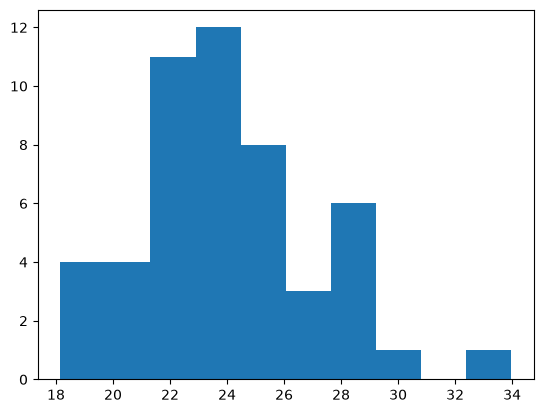

In [20]:
plt.hist(MSE)

**4. Compute the coefficient of variation of the MSEs**

In [25]:
std_mse = np.std(MSE, ddof=1)
print(std_mse)
mean_mse = np.mean(MSE)
print(mean_mse)
CV_mse = std_mse/mean_mse*100
print("The MSEs obtained with the validation set method have a coefficient of variation of:", CV_mse.round(2), "%.")

3.2121726696891595
23.89178515578629
The MSEs obtained with the validation set method have a coefficient of variation of: 13.44 %.
